In [55]:
from typing import List, TypedDict
import time
import os

from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
doc = PyPDFLoader("./data/book1.pdf").load()
len(doc)

In [18]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(doc)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [19]:
len(chunks)

2467

In [20]:
# embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base="https://openrouter.ai/api/v1",
)

In [21]:
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("my_faiss_index")

In [43]:
vector_store = FAISS.load_local("my_faiss_index", embeddings, allow_dangerous_deserialization=True)
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [56]:

# llm = ChatOpenAI(
#     # model="nvidia/nemotron-3.5-lightning:free",  # or any other OpenRouter model e.g. "google/gemini-2.0-flash-001"
#     model="openai/gpt-6-luna",
#     openai_api_key=os.getenv("OPENROUTER_API_KEY"),
#     openai_api_base="https://openrouter.ai/api/v1",
#     temperature=0.3,
# )

llm = ChatGroq(
    model="openai/gpt-oss-120b", 
    temperature=0.2,
    max_tokens=800
)

In [ ]:
class state(TypedDict):
    question : str
    need_retrieval: bool

    docs : list[Document]
    relevant_docs : list[Document]

    context: str
    answer : str

In [58]:
def retrieve(state):
    q = state["question"]
    return {"docs" : retriever.invoke(q)}

In [59]:
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

In [60]:
def generate(state):
    context = "/n/n".join(d.page_content for d in state["docs"])
    chain = prompt | llm
    response = chain.invoke({"question": state["question"], "context":context})
    # print(response)

    return {"answer": response.content}

In [95]:
from _winapi import VirtualQuerySize
class RelvenceDecision(BaseModel):
    is_relevant : bool = Field(description="True if the document helps answer the question, else False.")

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [   
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        )
    ]
)

relvenceLLM = llm.with_structured_output(RelvenceDecision)

def is_relevent(state : state):
    relevent_docs : List[Document] = []

    for doc in state["docs"]:
        out = relvenceLLM.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if out.is_relevant:
            relevent_docs.append(doc)
    
    return {"relevant_docs": relevent_docs} 

In [86]:
res = (is_relevant_prompt | relvenceLLM).invoke({"question":"hi","document": "doc"})

In [88]:
res.is_relevant

False

In [63]:
from typing import Literal
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )
    
decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: "state"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    return {"need_retrieval": decision.should_retrieve}

In [64]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)


def generate_direct(state: state):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {
        "answer": out.content
    }

In [65]:
def route_after_decision(state : state) -> Literal["retrieve", "generate_direct"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

In [ ]:
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business RAG assistant.\n"
            "Answer the user's question using ONLY the provided context.\n"
            "If the context does not contain enough information, say:\n"
            "'No relevant document found.'\n"
            "Do not use outside knowledge.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)

def generate_from_context(state: state):
    # Stuff relevant docs into one block
    context = "\n\n---\n\n".join(
        [d.page_content for d in state.get("relevant_docs", [])]
    ).strip()

    if not context:
        return {"answer": "No relevant document found.", "context": ""}

    out = llm.invoke(
        rag_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )
    return {"answer": out.content, "context": context}

In [116]:
graph = StateGraph(state)
graph.add_node("retrieve", retrieve)

graph.add_node("decide_retrieval", decide_retrieval)

graph.add_node("generate_direct", generate_direct)
graph.add_node("is_relevant", is_relevent)
graph.add_node("generate_from_context", generate_from_context)



graph.add_edge(START, "decide_retrieval")
graph.add_conditional_edges("decide_retrieval", route_after_decision,{
    "generate_direct":"generate_direct",
    "retrieve": "retrieve"
}
)
graph.add_edge("retrieve", "is_relevant")
graph.add_edge("is_relevant", "generate_from_context")
graph.add_edge("generate_from_context", END)
graph.add_edge("generate_direct", END)

app = graph.compile()

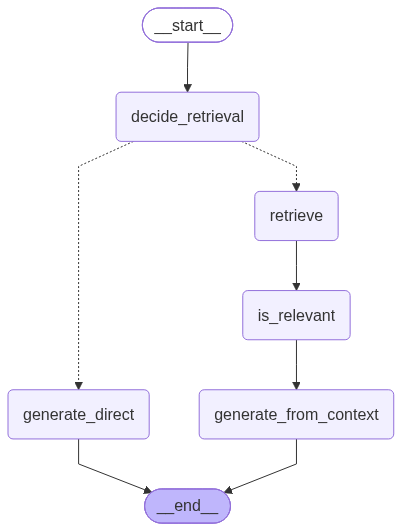

In [117]:
app

In [125]:
res = app.invoke({"question": "WHat is a neural network in deep learning from given book.","need_retrieval": 0, "docs": [], "relevant_docs":[], "answer": ""})
print(res["docs"])

[Document(id='055b3d40-8a5b-415b-8b0c-4d30f30637d8', metadata={'producer': 'Acrobat Distiller 6.0 (Windows)', 'creator': 'Adobe Acrobat 6.0', 'creationdate': '2006-10-18T12:52:36+08:00', 'author': 'Christopher M. Bishop', 'moddate': '2008-02-08T16:41:33+01:00', 'title': 'Pattern Recognition and Machine Learning', 'source': './data/book1.pdf', 'total_pages': 758, 'page': 247, 'page_label': '228'}, page_content='228 5. NEURAL NETWORKS\nFigure 5.1 Network diagram for the two-\nlayer neural network corre-\nsponding to (5.7). The input,\nhidden, and output variables\nare represented by nodes, and\nthe weight parameters are rep-\nresented by links between the\nnodes, in which the bias pa-\nrameters are denoted by links\ncoming from additional input\nand hidden variables x0 and\nz0. Arrows denote the direc-\ntion of information ﬂow through\nthe network during forward\npropagation. x0\nx1\nxD\nz0\nz1\nzM\ny1\nyK\nw(1)MD w(2)KM\nw(2)10\nhidden units\ninputs outputs\nand follows the same conside

In [126]:
len(res["docs"])

4

In [ ]:
res["relevant_docs"]
doc_content = "/n/n-----/n/n".join([d.page_content for d in res["relevant_docs"]])

In [128]:
res["answer"]

'A neural network is a model built from **layers of units**—an input layer, one or more hidden layers, and an output layer—whose nodes are linked by **weight parameters** (including bias links that come from extra input and hidden variables such as\u202fx₀ and\u202fz₀).  \n\nDuring **forward propagation**, information flows along the directed links from the inputs through the hidden units to the outputs. Each unit computes a weighted sum of its incoming signals and then applies an **activation function**: for standard regression the activation is the identity (so the output yₖ equals the activation aₖ), while for binary classification a logistic sigmoid is used (yₖ\u202f=\u202fσ(aₖ)). Hidden units may use other functions such as the hyperbolic tangent (tanh).  \n\nThe network can have various topologies: a general feed‑forward structure (Figure\u202f5.2), sparse connections, skip‑layer connections, or specialized forms such as **convolutional neural networks** that use local receptive 